## گام سوم پروژه: رسم نمودارها با Matplotlib
عنوان پروژه: تشخیص اعداد دست نویس

در این مرحله از فایل handwritten_digits_data.npz که در گام دوم ذخیره کردیم استفاده می کنیم. هدف این است که با استفاده از کتابخانه Matplotlib نمودارهایی رسم کنیم تا بتوانیم ویژگی های مجموعه داده و تفاوت اعداد دست نویس را بهتر بررسی کنیم.



### 1. بارگذاری کتابخانه ها و داده ها

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("handwritten_digits_data.npz")

print("فایل با موفقیت بارگذاری شد.")
print("کلیدهای موجود:", data.files)

X_train = data["train_images"]
y_train = data["train_labels"]

X_test = data["test_images"]
y_test = data["test_labels"]

print("تعداد تصاویر آموزش:", len(X_train))
print("تعداد تصاویر آزمون:", len(X_test))
print("ابعاد تصاویر:", X_train.shape[1:])

فایل با موفقیت بارگذاری شد.
کلیدهای موجود: ['train_images', 'train_labels', 'test_images', 'test_labels']
تعداد تصاویر آموزش: 59999
تعداد تصاویر آزمون: 9999
ابعاد تصاویر: (28, 28)


### 2. نمودار تعداد نمونه های هر عدد
در این قسمت تعداد تصاویر مربوط به هر عدد را محاسبه می کنیم و با استفاده از نمودار میله ای نمایش می دهیم. این نمودار به ما کمک می کند وضعیت توزیع نمونه ها در کلاس های مختلف را بررسی کنیم.

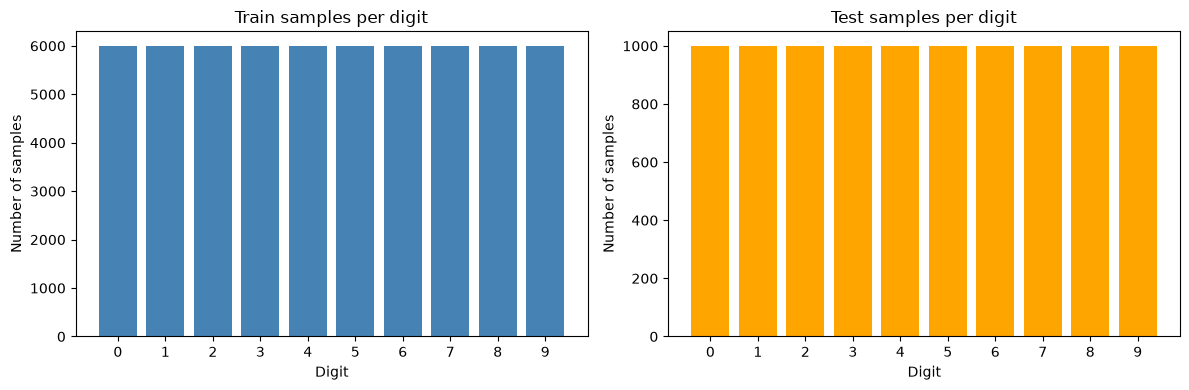

In [2]:
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

digits = np.arange(10)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(digits, train_counts, color="steelblue")
ax[0].set_title("Train samples per digit")
ax[0].set_xlabel("Digit")
ax[0].set_ylabel("Number of samples")
ax[0].set_xticks(digits)

ax[1].bar(digits, test_counts, color="orange")
ax[1].set_title("Test samples per digit")
ax[1].set_xlabel("Digit")
ax[1].set_ylabel("Number of samples")
ax[1].set_xticks(digits)

plt.tight_layout()
plt.show()

### 3. نمایش نمونه های اعداد دست نویس
در این قسمت چند نمونه از تصاویر موجود در مجموعه داده آموزش را نمایش می دهیم تا شکل نوشتن اعداد مختلف را مشاهده کنیم.

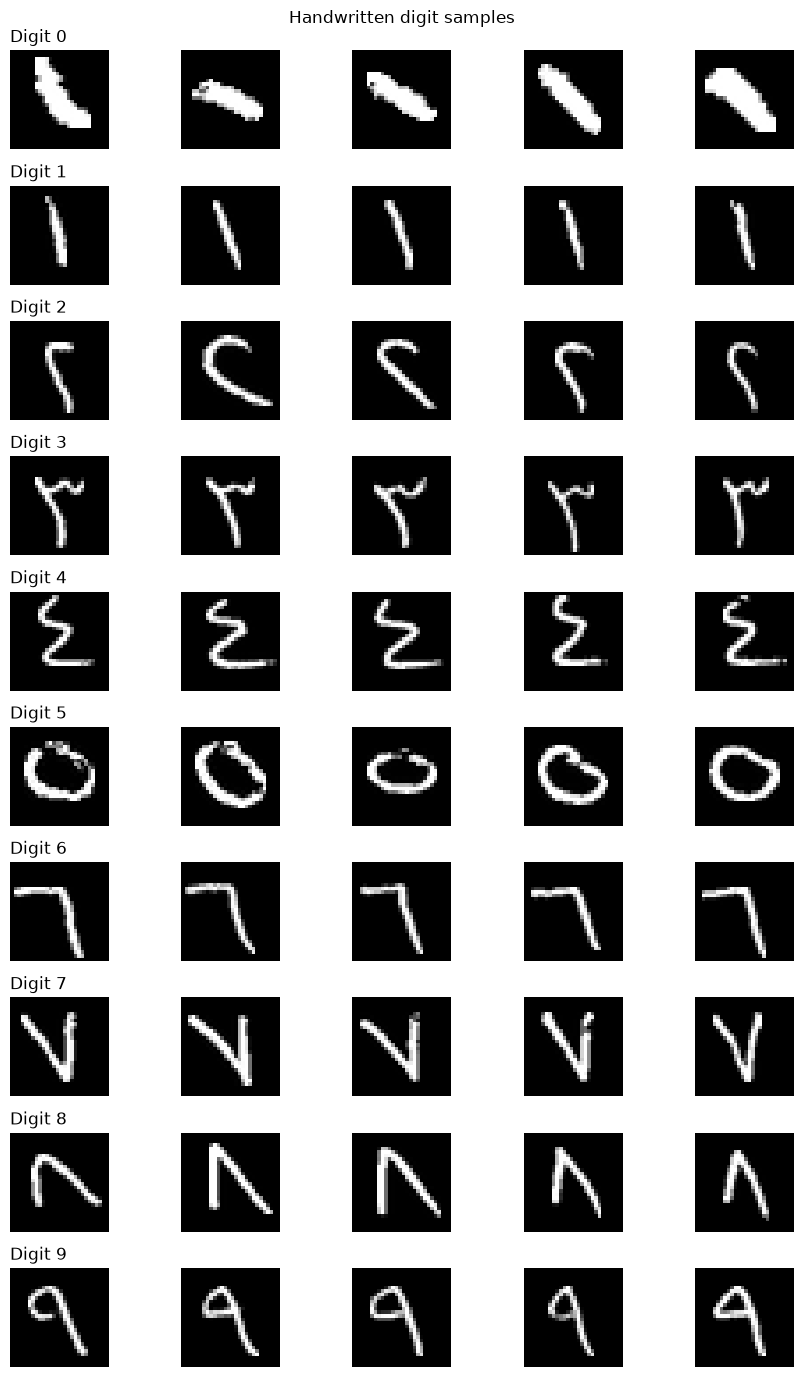

In [3]:
fig, axes = plt.subplots(10, 5, figsize=(9, 14))

for digit in range(10):

    indices = np.where(y_train == digit)[0]

    selected = indices[:5]

    for j in range(5):
        axes[digit, j].imshow(X_train[selected[j]], cmap="gray")
        axes[digit, j].axis("off")

        if j == 0:
            axes[digit, j].set_title(f"Digit {digit}", loc="left")

plt.suptitle("Handwritten digit samples")
plt.tight_layout()
plt.show()

### 4. نمودار توزیع شدت پیکسل ها
هر تصویر از تعدادی پیکسل تشکیل شده است. مقدار هر پیکسل نشان دهنده شدت روشنایی آن است. در این قسمت با استفاده از هیستوگرام، توزیع مقدار پیکسل های تصاویر آموزش را بررسی می کنیم.

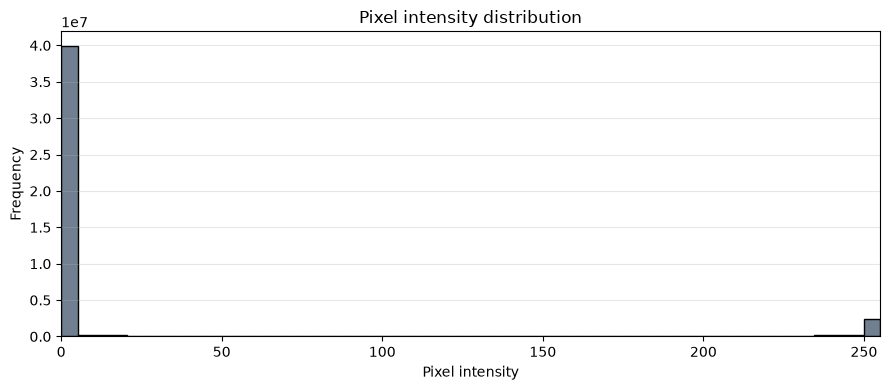

Minimum pixel value: 0
Maximum pixel value: 255
Average pixel value: 25.86


In [4]:
pixel_values = X_train.flatten()

plt.figure(figsize=(9, 4))

plt.hist(pixel_values, bins=50, color="slategray", edgecolor="black")

plt.title("Pixel intensity distribution")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")

plt.xlim(0, 255)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Minimum pixel value:", pixel_values.min())
print("Maximum pixel value:", pixel_values.max())
print("Average pixel value:", round(pixel_values.mean(), 2))

### 6. مقایسه میانگین شدت پیکسل اعداد
در این قسمت میانگین مقدار پیکسل تصاویر هر عدد را محاسبه می کنیم و نتیجه را به صورت نمودار میله ای نمایش می دهیم. این نمودار کمک می کند تفاوت کلی شدت روشنایی تصاویر کلاس های مختلف را بررسی کنیم.

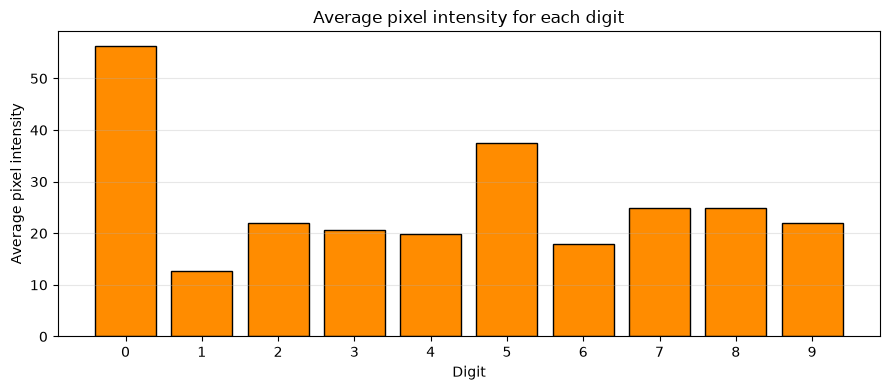

In [5]:
mean_values = []

for digit in range(10):

    digit_images = X_train[y_train == digit]

    mean_value = digit_images.mean()

    mean_values.append(mean_value)

plt.figure(figsize=(9, 4))

plt.bar(range(10), mean_values, color="darkorange", edgecolor="black")

plt.title("Average pixel intensity for each digit")
plt.xlabel("Digit")
plt.ylabel("Average pixel intensity")
plt.xticks(range(10))

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 7. نتیجه گیری
در این مرحله با استفاده از کتابخانه Matplotlib چند نمودار برای بررسی مجموعه داده اعداد دست نویس رسم کردیم.

با استفاده از این نمودارها توانستیم تعداد نمونه های هر عدد، شکل ظاهری تصاویر، توزیع شدت پیکسل ها و تصویر میانگین هر کلاس را بررسی کنیم.

این اطلاعات به ما کمک می کنند قبل از شروع آموزش مدل، شناخت بهتری از مجموعه داده داشته باشیم.